# 18 · Nối bảng và kiểm tra chất lượng

**Câu hỏi:** phép nối có giữ đúng tổng thể khách–tháng và lịch sử trước cutoff không?

Notebook quét toàn bộ raw TRX/GEO/DIALOG, kiểm tra khóa, orphan và nhãn; tính lại count theo tháng Moscow và đối chiếu cache/panel. Không lấy mẫu. Cell audit có thể mất vài phút và cần DuckDB; dừng nếu thiếu file hoặc đối soát sai.

Đơn vị mẫu: `(client_id, tháng nhãn)`. Cutoff 00:00 Moscow ngày đầu tháng; raw được diễn giải theo quy ước UTC rồi cộng 3 giờ để phân tháng. Quy ước này chưa xác minh timezone ETL. `mon` là định danh tháng nên không dịch timezone.

`client_split` (1/khách) → `targets` (1/khách–tháng) ← từng nguồn **đã tổng hợp** (1/khách–cutoff). LEFT JOIN giữ cả khách không có log; không nối hai bảng sự kiện chỉ theo client_id vì sẽ nhân dòng.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / 'data/MBD-mini').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/MBD-mini').exists(), 'Mở notebook trong thư mục dự án'
AUDIT = ROOT / 'outputs/eda_insights_20261119'
TARGET = ROOT / 'outputs/target_focused_moscow_20261119'
FIG = ROOT / 'outputs/eda_insights_20261119/charts'
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans', 'figure.dpi':120,
    'axes.spines.top':False, 'axes.spines.right':False, 'axes.titlesize':13})
def save_chart(fig, name):
    fig.tight_layout()
    for ext in ('png','svg'):
        fig.savefig(FIG / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
def read_audit(name):
    return pd.read_csv(AUDIT / name)


## Audit từ raw và dựng lại thẻ phân khúc
Cell dưới là mã audit được nhúng từ script, không chỉ đọc bảng kết quả cũ. Nó kiểm tra 12 tháng nhãn và dùng 10 cutoff đủ tương lai để so H1/H2/H3. H2/H3 là có mua trong ít nhất một trong 2/3 tháng kể từ tháng đích. Feature dùng mọi tháng trước cutoff.

In [2]:
"""Reconcile raw keys/monthly counts and produce EDA evidence, without training."""
from pathlib import Path
import json
import duckdb
import pandas as pd

# ROOT được xác định ở cell thiết lập notebook
OUT = ROOT / 'outputs/eda_insights_20261119'
OUT.mkdir(parents=True, exist_ok=True)
BASE = ROOT / 'outputs/full_population_temporal_eda_20261118'
c = duckdb.connect()
c.execute("SET memory_limit='3GB'")
c.execute('SET threads=2')
c.execute(f"SET temp_directory='{OUT.as_posix()}/tmp'")

def path(p):
    return str(p).replace('\\', '/').replace("'", "''")

c.execute(f"CREATE VIEW clients AS SELECT * FROM read_parquet('{path(ROOT/'data/MBD-mini/client_split/**/*.parquet')}')")
c.execute(f"CREATE VIEW labels AS SELECT *, date_trunc('month',cast(mon AS DATE)) AS month, greatest(target_1,target_2,target_3,target_4) AS y FROM read_parquet('{path(ROOT/'data/MBD-mini/targets/**/*.parquet')}')")
n = c.execute('SELECT count(*) FROM clients').fetchone()[0]
checks = {}
checks['clients_unique_nonnull'] = c.execute('SELECT count(*)=count(DISTINCT client_id) FROM clients').fetchone()[0]
checks['label_keys_unique_nonnull'] = c.execute('SELECT count(*)=count(DISTINCT (client_id,month)) AND count(client_id)=count(*) AND count(month)=count(*) FROM labels').fetchone()[0]
checks['labels_binary_complete'] = c.execute('SELECT count(*) FROM labels WHERE ' + ' OR '.join(f'target_{i} IS NULL OR target_{i} NOT IN (0,1)' for i in range(1,5))).fetchone()[0] == 0
checks['label_ids_match'] = c.execute('SELECT count(*) FROM labels l ANTI JOIN clients c USING(client_id)').fetchone()[0] == 0
monthly = c.execute('SELECT month,count(*) n,sum(y) buyers,avg(y) rate FROM labels GROUP BY 1 ORDER BY 1').df()
checks['complete_12_months'] = len(monthly) == 12 and monthly.n.eq(n).all()
monthly.to_csv(OUT/'label_monthly.csv', index=False)
audit = []
for s in ['trx','geo','dialog']:
    print('Audit raw and reconcile Moscow monthly counts:', s, flush=True)
    c.execute(f"CREATE OR REPLACE VIEW events AS SELECT client_id,event_time FROM read_parquet('{path(ROOT/f'data/MBD-mini/detail/{s}/**/*.parquet')}')")
    row = c.execute("SELECT count(*) rows,count(DISTINCT client_id) customers,count(*) FILTER(WHERE client_id IS NULL) null_ids,count(*) FILTER(WHERE event_time IS NULL) null_times FROM events").df().iloc[0].to_dict()
    row['source'] = s
    row['orphan_events'] = c.execute('SELECT count(*) FROM events e ANTI JOIN clients c USING(client_id)').fetchone()[0]
    c.execute("CREATE OR REPLACE TEMP TABLE raw_monthly AS SELECT client_id,date_trunc('month',event_time+INTERVAL '3 hours') AS month,count(*) n FROM events GROUP BY 1,2")
    cached = path(BASE/f'{s}_monthly.parquet')
    mismatch = c.execute(f"SELECT count(*) FROM raw_monthly r FULL JOIN read_parquet('{cached}') a USING(client_id,month) WHERE r.n IS DISTINCT FROM a.{s}_events").fetchone()[0]
    row['monthly_mismatches'] = mismatch
    checks[f'{s}_raw_keys_and_cache'] = not any(row[k] for k in ['null_ids','null_times','orphan_events','monthly_mismatches'])
    audit.append(row)
pd.DataFrame(audit).to_csv(OUT/'join_audit.csv',index=False)
print('Audit amount distribution', flush=True)
c.execute(f"CREATE VIEW trx AS SELECT amount,currency FROM read_parquet('{path(ROOT/'data/MBD-mini/detail/trx/**/*.parquet')}')")
c.execute('SELECT currency,count(*) n,count(*) FILTER(WHERE amount IS NULL) missing_amount,count(*) FILTER(WHERE amount=0) zero_amount,count(*) FILTER(WHERE amount<0) negative_amount,min(amount) minimum,quantile_cont(amount,0.5) median,quantile_cont(amount,0.99) p99,max(amount) maximum FROM trx GROUP BY 1 ORDER BY n DESC').df().to_csv(OUT/'amount_by_currency.csv',index=False)

# Rebuild the common-cohort features from reconciled source-month counts.
c.execute(f"CREATE VIEW panel AS SELECT * FROM read_parquet('{path(BASE/'all_customer_months.parquet')}')")
checks['panel_keys_unique'] = c.execute('SELECT count(*)=count(DISTINCT (client_id,month)) FROM panel').fetchone()[0]
for s in ['trx','geo','dialog']:
    checks[f'{s}_panel_matches_cache'] = c.execute(f"SELECT count(*) FROM panel p FULL JOIN read_parquet('{path(BASE/f'{s}_monthly.parquet')}') a USING(client_id,month) WHERE coalesce(p.{s}_events,0) IS DISTINCT FROM coalesce(a.{s}_events,0)").fetchone()[0] == 0
checks['panel_labels_match_raw'] = c.execute('SELECT count(*) FROM labels l LEFT JOIN panel p USING(client_id,month) WHERE l.y IS DISTINCT FROM p.y').fetchone()[0] == 0
d = c.execute("""WITH h AS (
 SELECT client_id,month,y,
 sum(coalesce(trx_events,0)) OVER w trx_hist,
 sum(coalesce(geo_events,0)) OVER w geo_hist,
 sum(coalesce(dialog_events,0)) OVER w dialog_hist,
 max(CASE WHEN dialog_events>0 THEN month END) OVER w last_dialog,
 lead(y,1) OVER (PARTITION BY client_id ORDER BY month) y2,
 lead(y,2) OVER (PARTITION BY client_id ORDER BY month) y3
 FROM panel WINDOW w AS (PARTITION BY client_id ORDER BY month ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING))
 SELECT *,date_diff('month',last_dialog,month)=1 dialog_recent FROM h
 WHERE y IS NOT NULL AND y2 IS NOT NULL AND y3 IS NOT NULL""").df()
d['dialog_recent'] = d.dialog_recent.fillna(False)
d['trx_band'] = pd.cut(d.trx_hist.fillna(0),[-1,0,9,99,float('inf')],labels=['0','1-9','10-99','100+'])
d['source_count'] = d[['trx_hist','geo_hist','dialog_hist']].fillna(0).gt(0).sum(axis=1)
checks['common_cohort'] = len(d)==n*10 and d.groupby('month').client_id.nunique().eq(n).all()
for h in [1,2,3]:
    d[f'h{h}'] = d[['y','y2','y3'][:h]].max(axis=1)
rows=[]
for feature in ['dialog_recent','trx_band','source_count']:
    for (month,group),a in d.groupby(['month',feature],observed=True):
        baseline=d.loc[d.month.eq(month)]
        for h in [1,2,3]:
            buyers=int(a[f'h{h}'].sum()); total=int(baseline[f'h{h}'].sum())
            rows.append(dict(feature=feature,month=month,group=str(group),horizon=h,n=len(a),buyers=buyers,rate=buyers/len(a),population_share=len(a)/len(baseline),buyer_share=buyers/total,lift=(buyers/len(a))/(total/len(baseline))))
segments=pd.DataFrame(rows)
segments.to_csv(OUT/'monthly_segment_cards.csv',index=False)
pooled=segments.groupby(['feature','group','horizon'],as_index=False).agg(n=('n','sum'),buyers=('buyers','sum'),min_monthly_lift=('lift','min'),max_monthly_lift=('lift','max'))
pooled['rate']=pooled.buyers/pooled.n
pooled['population_share']=pooled.n/len(d)
totals={h:int(d[f'h{h}'].sum()) for h in [1,2,3]}
pooled['buyer_share']=[b/totals[h] for b,h in zip(pooled.buyers,pooled.horizon)]
pooled['lift']=pooled.rate/[totals[h]/len(d) for h in pooled.horizon]
pooled.to_csv(OUT/'segment_cards.csv',index=False)
checks['all_segments_reconcile']=bool(segments.groupby(['feature','month','horizon']).n.sum().eq(n).all())
checks={k:bool(v) for k,v in checks.items()}
(OUT/'validation.json').write_text(json.dumps(checks,indent=2),encoding='utf-8')
assert all(checks.values()),checks
print(json.dumps(checks,indent=2),flush=True)
print(pooled[pooled.horizon.eq(1)].to_string(index=False),flush=True)


Audit raw and reconcile Moscow monthly counts: trx


Audit raw and reconcile Moscow monthly counts: geo


Audit raw and reconcile Moscow monthly counts: dialog


Audit amount distribution


{
  "clients_unique_nonnull": true,
  "label_keys_unique_nonnull": true,
  "labels_binary_complete": true,
  "label_ids_match": true,
  "complete_12_months": true,
  "trx_raw_keys_and_cache": true,
  "geo_raw_keys_and_cache": true,
  "dialog_raw_keys_and_cache": true,
  "panel_keys_unique": true,
  "trx_panel_matches_cache": true,
  "geo_panel_matches_cache": true,
  "dialog_panel_matches_cache": true,
  "panel_labels_match_raw": true,
  "common_cohort": true,
  "all_segments_reconcile": true
}


      feature group  horizon      n  buyers  min_monthly_lift  max_monthly_lift     rate  population_share  buyer_share     lift
dialog_recent False        1 944566    8984          0.754543          0.913178 0.009511          0.942455     0.786690 0.834724
dialog_recent  True        1  57674    2436          3.315107          5.136089 0.042237          0.057545     0.213310 3.706831
 source_count     0        1  32792     316          0.392966          3.455393 0.009636          0.032719     0.027671 0.845717
 source_count     1        1 250770    1605          0.455733          0.668068 0.006400          0.250210     0.140543 0.561701
 source_count     2        1 463500    4456          0.667420          0.953365 0.009614          0.462464     0.390193 0.843725
 source_count     3        1 255178    5043          1.555180          2.113103 0.019763          0.254608     0.441594 1.734408
     trx_band     0        1  84670    1190          0.546615          3.409510 0.014055         

## Kết quả kiểm tra
Mỗi dòng kiểm tra phải đạt. Count cache khớp raw chưa chứng minh ETL gốc đầy đủ; nó xác nhận tính nhất quán giữa các artifact hiện có.

In [3]:
checks=json.loads((AUDIT/'validation.json').read_text())
display(pd.DataFrame({'check':checks.keys(),'passed':checks.values()}))
assert all(checks.values())
join=read_audit('join_audit.csv')
display(join)

,check,passed
0,clients_unique_nonnull,True
1,label_keys_unique_nonnull,True
2,labels_binary_complete,True
3,label_ids_match,True
4,complete_12_months,True
5,trx_raw_keys_and_cache,True
6,geo_raw_keys_and_cache,True
7,dialog_raw_keys_and_cache,True
8,panel_keys_unique,True
9,trx_panel_matches_cache,True


,rows,customers,null_ids,null_times,source,orphan_events,monthly_mismatches
0,38764930,98721,0,0,trx,0,0
1,66295724,72573,0,0,geo,0,0
2,217205,46320,0,0,dialog,0,0


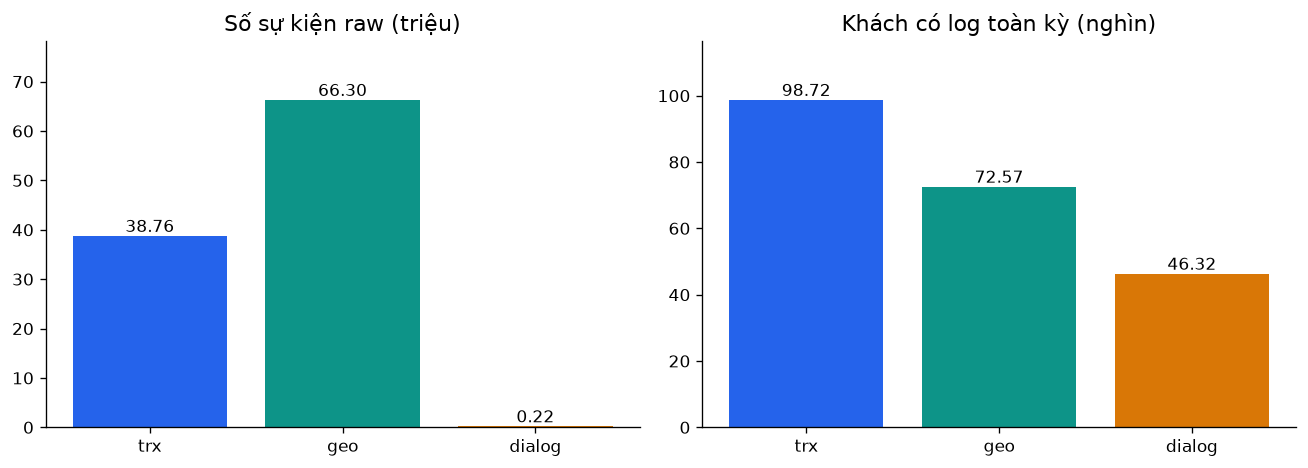

In [4]:
fig, axes=plt.subplots(1,2,figsize=(11,4))
colors=['#2563eb','#0d9488','#d97706']
for ax,col,title,scale in [(axes[0],'rows','Số sự kiện raw (triệu)',1e6),(axes[1],'customers','Khách có log toàn kỳ (nghìn)',1e3)]:
    vals=join[col]/scale
    ax.bar(join.source, vals, color=colors)
    for i,v in enumerate(vals): ax.text(i,v,f'{v:,.2f}',ha='center',va='bottom')
    ax.set_title(title); ax.set_ylim(0,max(vals)*1.18)
save_chart(fig,'18_source_inventory')

**Diễn giải:** độ phủ khách khác nhau giữa các nguồn; inner join cả ba sẽ làm đổi tổng thể. Số khách có log toàn kỳ không phải số khách có lịch sử tại mọi cutoff. 0 count là không ghi nhận log, không chứng minh không hoạt động.

## Checklist join
- [x] Khóa khách và khách–tháng duy nhất; đủ 12 tháng nhãn.
- [x] Null khóa/thời gian, orphan, count theo tháng và nhãn được đối soát.
- [x] Giữ khách thiếu nguồn; phân khúc cộng đúng tổng thể.
- [ ] Xác minh timezone ETL và thời điểm nhãn sẵn có.
- [ ] Kiểm tra near-duplicate và mapping detail–PTLS nếu dùng PTLS.

Xem notebook 19 cho đơn biến và notebook 20 cho quan hệ với target.